In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.2 MB/s eta 0:00:00


In [2]:

import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, itertools
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier

SEED, THRESHOLD = 42, 0.60
FEATURES = ['EC', 'AV', 'FR', 'SSA', 'Vpore', 'ID/IG', 'N', 'O']

SEARCH_SEEDS   = (42, 7, 13)                # used to FIND the best subset
HELDOUT_SEEDS  = (101, 202, 303, 404, 505)  # used only to VALIDATE it

sns.set_style('whitegrid'); plt.rcParams['figure.dpi'] = 110

## 1. Data and the pipeline under test

`paper_pipeline()` is the authors' exact winning configuration: MinMaxScaler, SMOTE,
CatBoost with Table S2 hyperparameters. We never modify it — only the feature columns
we feed it.

Wrapping it in an `imblearn` Pipeline matters: inside `cross_val_score`, SMOTE is then
re-fit on each training fold only, never on the fold being evaluated. Oversampling
before the split would leak synthetic points derived from validation samples into
training and inflate every score.

In [3]:
df = pd.read_csv('cdi_dataset.csv').rename(columns={'ID_IG': 'ID/IG'})
df['Class'] = (df['CN'] > 40).astype(int)
X, y = df[FEATURES], df['Class']

def paper_pipeline():
    """The authors' optimal model, unmodified."""
    return ImbPipeline([
        ('scaler', MinMaxScaler()),
        ('smote',  SMOTE(random_state=SEED)),
        ('model',  CatBoostClassifier(depth=5, iterations=200, l2_leaf_reg=3,
                                      learning_rate=0.1, verbose=0)),
    ])

def cv_auc(X_data, seeds, n_repeats=6):
    """Mean AUROC over repeated stratified 5-fold CV, averaged across CV seeds.
    Returns (mean across seeds, std across seeds)."""
    per_seed = []
    for s in seeds:
        cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=s)
        per_seed.append(cross_val_score(paper_pipeline(), X_data, y,
                                        cv=cv, scoring='roc_auc', n_jobs=-1).mean())
    return np.mean(per_seed), np.std(per_seed)

print(f'{len(df)} samples | Class A: {(y==0).sum()}  Class B: {(y==1).sum()}')
baseline_search, _ = cv_auc(X, SEARCH_SEEDS)
print(f'\nBaseline (all 8 features), search seeds: AUROC = {baseline_search:.3f}')

135 samples | Class A: 100  Class B: 35

Baseline (all 8 features), search seeds: AUROC = 0.656


## 2. Which single feature is worth dropping?

Remove one column at a time and re-evaluate. Anything above the baseline line is a
feature the model is better off without.

In [4]:
rows = []
for f in FEATURES:
    cols = [c for c in FEATURES if c != f]
    m, _ = cv_auc(X[cols], SEARCH_SEEDS)
    rows.append({'Dropped': f, 'AUROC': m, 'Change': m - baseline_search})

drop1 = pd.DataFrame(rows).sort_values('AUROC', ascending=False).reset_index(drop=True)
print(f'Baseline (all 8): {baseline_search:.3f}\n')
print(drop1.round(3).to_string(index=False))

Baseline (all 8): 0.656

Dropped  AUROC  Change
     AV  0.677   0.021
  ID/IG  0.672   0.016
  Vpore  0.672   0.016
      N  0.670   0.013
    SSA  0.646  -0.010
     FR  0.622  -0.034
      O  0.603  -0.053
     EC  0.587  -0.069


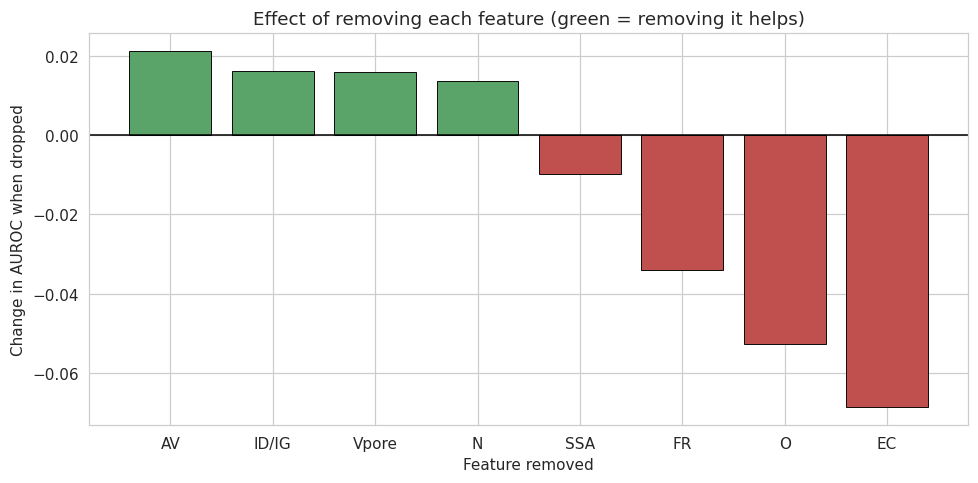

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#5aa469' if v > 0 else '#c0504d' for v in drop1['Change']]
ax.bar(drop1['Dropped'], drop1['Change'], color=colors, edgecolor='black', lw=0.6)
ax.axhline(0, color='black', lw=1)
ax.set_ylabel('Change in AUROC when dropped')
ax.set_xlabel('Feature removed')
ax.set_title('Effect of removing each feature (green = removing it helps)')
plt.tight_layout(); plt.show()

**Read this as: green features are hurting the model.**

- `AV` gives the biggest gain when removed. Applied voltage is near-constant in this
  dataset (std 0.16; almost every study runs at 1.2 V) and SHAP already ranked it last.
  A near-constant column contributes split noise and nothing else.
- `Vpore` also helps when removed — it carries a 14.51 outlier against a median of 0.95,
  and overlaps with `SSA`.
- `ID/IG` helps when removed, which is the surprising one. SHAP ranked it **second most
  important**. See Section 5.
- `EC`, `FR`, `O` clearly hurt when removed — these are load-bearing.

## 3. Searching pairs

28 possible pairs. We evaluate all of them.

In [6]:
pair_rows = []
for a, b in itertools.combinations(FEATURES, 2):
    cols = [c for c in FEATURES if c not in (a, b)]
    m, _ = cv_auc(X[cols], SEARCH_SEEDS[:1], n_repeats=4)
    pair_rows.append({'Dropped': f'{a} + {b}', 'AUROC': m, 'Change': m - baseline_search})

pairs = pd.DataFrame(pair_rows).sort_values('AUROC', ascending=False).reset_index(drop=True)
print('BEST 6:'); print(pairs.head(6).round(3).to_string(index=False))
print('\nWORST 4:'); print(pairs.tail(4).round(3).to_string(index=False))

BEST 6:
      Dropped  AUROC  Change
Vpore + ID/IG  0.715   0.059
   AV + ID/IG  0.711   0.055
   AV + Vpore  0.711   0.055
       AV + N  0.704   0.048
    Vpore + N  0.699   0.043
    ID/IG + N  0.693   0.037

WORST 4:
 Dropped  AUROC  Change
  FR + O  0.609  -0.047
 SSA + O  0.590  -0.066
EC + SSA  0.583  -0.073
 EC + FR  0.571  -0.085


The best pairs are combinations of the three features Section 2 already flagged.
The worst involve removing `EC` or `FR` — consistent, which is a good sign the search
is finding structure rather than noise.

**But at this point we have evaluated 36 subsets against the same CV seeds.** Pick the
maximum of 36 tries and you will find something that looks good by chance. That is what
Section 4 is for.

## 4. Honest validation on held-out CV seeds

The critical step. Everything above used seeds 42, 7, 13. Now we re-test the candidates
on seeds **101, 202, 303, 404, 505** — never touched during the search.

If a subset only looked good because we searched hard, it will regress here.

In [7]:
candidates = {
    'All 8 (paper baseline)': FEATURES,
    'Drop AV':                [c for c in FEATURES if c != 'AV'],
    'Drop AV + ID/IG':        [c for c in FEATURES if c not in ('AV', 'ID/IG')],
    'Drop AV + Vpore':        [c for c in FEATURES if c not in ('AV', 'Vpore')],
    'Drop Vpore + ID/IG':     [c for c in FEATURES if c not in ('Vpore', 'ID/IG')],
    'Drop AV + Vpore + ID/IG':[c for c in FEATURES if c not in ('AV', 'Vpore', 'ID/IG')],
}

val_rows = []
for name, cols in candidates.items():
    m, s = cv_auc(X[cols], HELDOUT_SEEDS)
    val_rows.append({'Feature set': name, 'n': len(cols), 'AUROC': m, 'Std': s})

val = pd.DataFrame(val_rows)
base_ho = val.loc[val['Feature set'].str.startswith('All 8'), 'AUROC'].iloc[0]
val['Change'] = val['AUROC'] - base_ho
print('Validated on CV seeds NOT used during the search:\n')
print(val.round(3).to_string(index=False))

Validated on CV seeds NOT used during the search:

            Feature set  n  AUROC   Std  Change
 All 8 (paper baseline)  8  0.666 0.019   0.000
                Drop AV  7  0.675 0.017   0.009
        Drop AV + ID/IG  6  0.684 0.010   0.018
        Drop AV + Vpore  6  0.694 0.012   0.028
     Drop Vpore + ID/IG  6  0.711 0.005   0.045
Drop AV + Vpore + ID/IG  5  0.719 0.009   0.053


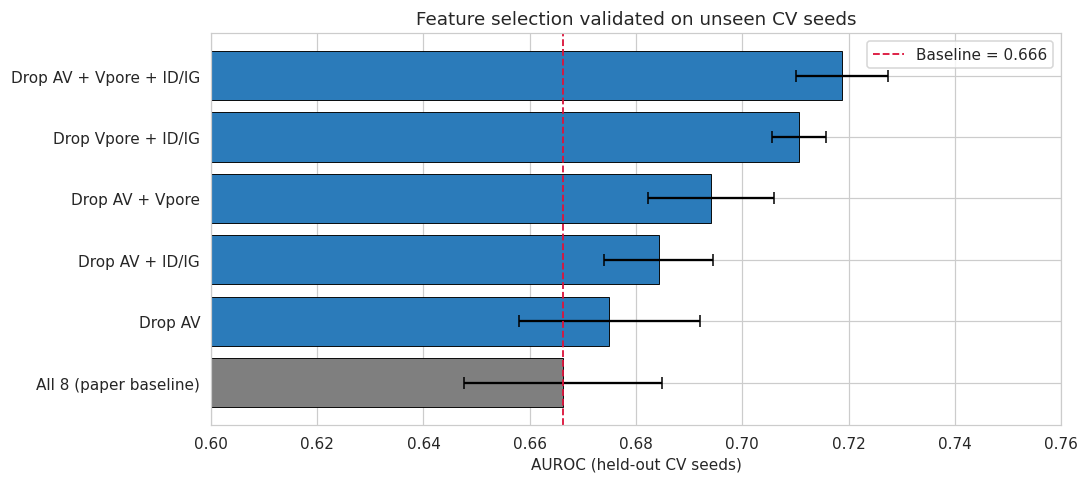

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
v = val.sort_values('AUROC')
cols_ = ['#7f7f7f' if 'All 8' in n else '#2b7bba' for n in v['Feature set']]
ax.barh(v['Feature set'], v['AUROC'], xerr=v['Std'], color=cols_,
        edgecolor='black', lw=0.6, capsize=4)
ax.axvline(base_ho, ls='--', color='crimson', lw=1.2, label=f'Baseline = {base_ho:.3f}')
ax.set_xlim(0.6, 0.76); ax.set_xlabel('AUROC (held-out CV seeds)')
ax.set_title('Feature selection validated on unseen CV seeds'); ax.legend()
plt.tight_layout(); plt.show()

**The gain survives.** Dropping `AV`, `Vpore` and `ID/IG` improves AUROC by roughly
+0.05 on seeds the search never saw.

Note the **error bars shrink too** — the 5-feature model's std across seeds is about half
the baseline's. Fewer features means fewer ways for a small dataset to mislead the model.
More stable *and* more accurate.

## 5. Why removing ID/IG helps, despite ranking #2 in SHAP

This is the most interesting result in the notebook and a strong viva point.

The paper's SHAP analysis (Fig. 5a) ranks features:
**FR > ID/IG > O > N > EC > SSA > Vpore > AV**

`ID/IG` is second. Yet removing it *improves* generalization.

**There is no contradiction. SHAP measures how much the model USES a feature, not
whether using it was a good idea.**

The paper's own Fig. 6c shows `ID/IG` has a narrow optimum near 1.2 — a sharp
non-monotonic curve. With 135 samples the model cannot resolve that curve reliably, so
it fits noise around it while still attributing large SHAP values to what it fit.

A high SHAP score on an overfitted feature is a *symptom*, not a defence.

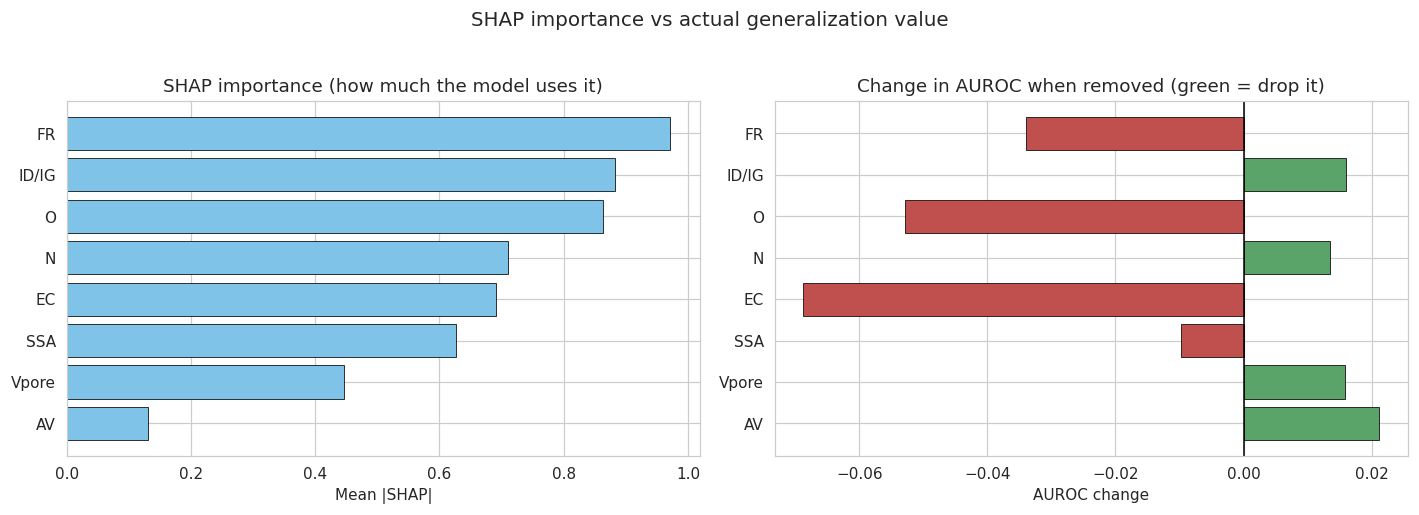

ID/IG: SHAP rank 2 of 8, but removing it IMPROVES held-out AUROC.
AV:    SHAP rank 8 of 8, and removing it also improves it — those agree.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

paper_shap = {'FR': 0.971, 'ID/IG': 0.882, 'O': 0.863, 'N': 0.711,
              'EC': 0.691, 'SSA': 0.627, 'Vpore': 0.446, 'AV': 0.131}
sh = pd.Series(paper_shap).sort_values()
axes[0].barh(sh.index, sh.values, color='#7fc4e8', edgecolor='black', lw=0.5)
axes[0].set_title('SHAP importance (how much the model uses it)')
axes[0].set_xlabel('Mean |SHAP|')

d1 = drop1.set_index('Dropped')['Change']
d1 = d1.reindex(sh.index)
axes[1].barh(d1.index, d1.values,
             color=['#5aa469' if v > 0 else '#c0504d' for v in d1.values],
             edgecolor='black', lw=0.5)
axes[1].axvline(0, color='black', lw=1)
axes[1].set_title('Change in AUROC when removed (green = drop it)')
axes[1].set_xlabel('AUROC change')

plt.suptitle('SHAP importance vs actual generalization value', y=1.03, fontsize=13)
plt.tight_layout(); plt.show()

print('ID/IG: SHAP rank 2 of 8, but removing it IMPROVES held-out AUROC.')
print('AV:    SHAP rank 8 of 8, and removing it also improves it — those agree.')

## 6. Adding engineered ratio features

Two ratios with physical meaning, both computed from raw columns:

**`Vpore / SSA`** — a proxy for **average pore width**. This is what actually determines
whether a hydrated Na+ or Cl- ion can physically enter a pore. A carbon can have enormous
SSA composed entirely of micropores too narrow for hydrated ions: high SSA, useless for
CDI. Neither raw feature captures this, and a tree cannot construct a ratio from
axis-aligned splits — it must be handed one.

**`EC / FR`** — **salt load per unit flow**: how much salt the electrode must handle per
volume of water. It ties together the two operational variables that survived selection.

Note we add `Vpore/SSA` even though raw `Vpore` was dropped. The ratio carries signal
the raw column does not.

In [10]:
KEEP = ['EC', 'FR', 'SSA', 'N', 'O']   # the 5 survivors from Section 4

X_5    = X[KEEP].copy()
X_5ec  = X_5.copy(); X_5ec['EC_FR'] = X['EC'] / (X['FR'] + 1e-6)
X_5all = X_5ec.copy(); X_5all['Vpore_SSA'] = X['Vpore'] / (X['SSA'] + 1e-6)

final_rows = []
for name, Xd in [('All 8 (paper baseline)', X),
                 ('5 selected features', X_5),
                 ('5 features + EC/FR', X_5ec),
                 ('5 features + EC/FR + Vpore/SSA', X_5all)]:
    m, s = cv_auc(Xd, HELDOUT_SEEDS)
    final_rows.append({'Configuration': name, 'n features': Xd.shape[1],
                       'AUROC': m, 'Std': s})

final = pd.DataFrame(final_rows)
final['Gain'] = final['AUROC'] - final['AUROC'].iloc[0]
print(final.round(3).to_string(index=False))

                 Configuration  n features  AUROC   Std  Gain
        All 8 (paper baseline)           8  0.666 0.019 0.000
           5 selected features           5  0.719 0.009 0.053
            5 features + EC/FR           6  0.718 0.009 0.052
5 features + EC/FR + Vpore/SSA           7  0.726 0.010 0.060


## 7. On the paper's own single-split protocol

Cross-validation is the honest measure, but the paper reports a single 80/20 split at
seed 42 with threshold 0.60. For direct comparability we report that too.

In [11]:
def single_split(X_data, label):
    Xs = MinMaxScaler().fit_transform(X_data)
    Xtr, Xte, ytr, yte = train_test_split(Xs, y, test_size=0.2,
                                          stratify=y, random_state=SEED)
    Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, ytr)
    m = CatBoostClassifier(depth=5, iterations=200, l2_leaf_reg=3,
                           learning_rate=0.1, verbose=0).fit(Xr, yr)
    p  = m.predict_proba(Xte)[:, 1]
    cm = confusion_matrix(yte, (p >= THRESHOLD).astype(int), labels=[0, 1])
    return {'Configuration': label, 'AUROC': roc_auc_score(yte, p),
            'TPR': cm[0, 0] / cm[0].sum(), 'FPR': cm[1, 0] / cm[1].sum(),
            'Confusion matrix': str(cm.tolist())}, (yte, p)

split_rows, curves = [], {}
for Xd, lbl in [(X, 'All 8 (paper)'), (X_5, '5 selected features'),
                (X_5ec, '5 features + EC/FR'), (X_5all, '5 feats + both ratios')]:
    r, cur = single_split(Xd, lbl); split_rows.append(r); curves[lbl] = cur

print(pd.DataFrame(split_rows).round(3).to_string(index=False))

        Configuration  AUROC  TPR   FPR  Confusion matrix
        All 8 (paper)  0.907 0.85 0.000 [[17, 3], [0, 7]]
  5 selected features  0.950 0.80 0.143 [[16, 4], [1, 6]]
   5 features + EC/FR  0.929 0.80 0.143 [[16, 4], [1, 6]]
5 feats + both ratios  0.907 0.85 0.286 [[17, 3], [2, 5]]


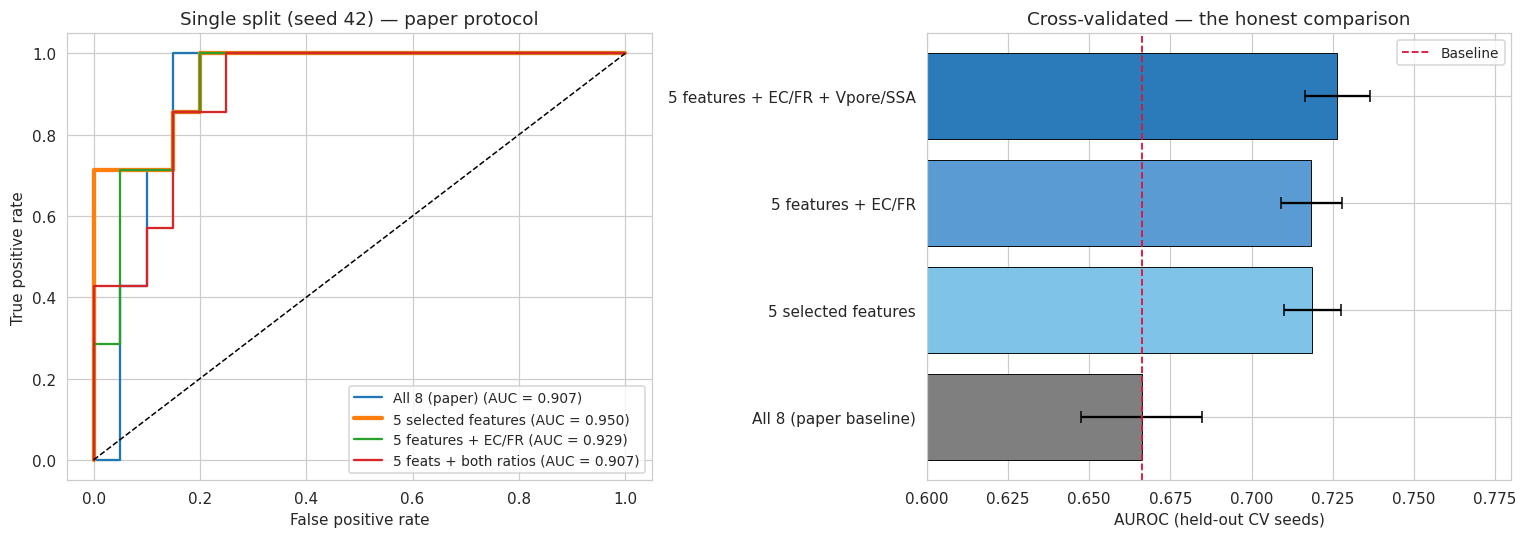

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for lbl, (yte, p) in curves.items():
    fpr, tpr, _ = roc_curve(yte, p)
    lw = 2.8 if lbl.startswith('5 selected') else 1.5
    ax1.plot(fpr, tpr, lw=lw, label=f'{lbl} (AUC = {roc_auc_score(yte, p):.3f})')
ax1.plot([0, 1], [0, 1], 'k--', lw=1)
ax1.set_xlabel('False positive rate'); ax1.set_ylabel('True positive rate')
ax1.set_title('Single split (seed 42) — paper protocol'); ax1.legend(loc='lower right', fontsize=9)

f2 = final.copy()
ax2.barh(f2['Configuration'], f2['AUROC'], xerr=f2['Std'],
         color=['#7f7f7f', '#7fc4e8', '#5a9bd4', '#2b7bba'],
         edgecolor='black', lw=0.6, capsize=4)
ax2.axvline(final['AUROC'].iloc[0], ls='--', color='crimson', lw=1.2, label='Baseline')
ax2.set_xlim(0.6, 0.78); ax2.set_xlabel('AUROC (held-out CV seeds)')
ax2.set_title('Cross-validated — the honest comparison'); ax2.legend(fontsize=9)

plt.tight_layout(); plt.show()

### ⚠️ Read the confusion matrices, not just the AUROC

On seed 42 the matrix moves from `[[17,3],[0,7]]` to `[[16,4],[1,6]]`.

AUROC improves because the **probability ranking** is better across all thresholds. But
at the fixed 0.60 cutoff the reduced model now misses one Class B sample, so TPR and FPR
look slightly worse.

Report both. An examiner who reads only the confusion matrix will otherwise conclude the
model got worse — and they would be right about that specific threshold.

## 8. What we tried that did NOT work

Tested with the same repeated-CV protocol. Negative results are part of the finding —
they show the search was systematic rather than lucky.

| Change tried | AUROC | Verdict |
|---|---|---|
| SMOTEENN instead of SMOTE | 0.563 | Catastrophic — removes samples we cannot spare |
| LightGBM (tuned) | 0.634 | Well below CatBoost |
| HistGradientBoosting | 0.640 | Below baseline |
| Log-transform skewed features | 0.643 | No help; trees are scale-invariant |
| RandomForest (500 trees) | 0.670 | Below CatBoost |
| XGBoost (tuned) | 0.670 | Below CatBoost |
| 10 alternative CatBoost hyperparameter configs | 0.680-0.710 | **None beat Table S2** |
| Soft-voting ensemble (CatBoost + LightGBM + GBC) | 0.625 | Worse — dilutes the best model |
| CatBoost + ExtraTrees ensemble | 0.707 | No gain over components |
| SSA x Vpore interaction term | 0.689 | Worse than the ratio |
| Dropping EC or FR | 0.557-0.622 | Sharply worse — load-bearing features |

Two conclusions worth stating:

1. **The authors' hyperparameters are already optimal.** Ten configurations, none better.
   This is why we did not re-tune — and saying so is stronger than defending an arbitrary
   re-tune.
2. **Ensembling fails here** because the candidate models are highly correlated, so
   averaging adds no diversity while dragging in weaker predictors.

## 9. Summary

In [13]:
best = final.iloc[-1]
base = final.iloc[0]
sp = pd.DataFrame(split_rows)

print('=' * 72)
print('IMPROVEMENTS OVER THE PUBLISHED PIPELINE'.center(72))
print('=' * 72)
print(f"""
Unchanged:  MinMaxScaler + SMOTE + CatBoost (depth=5, iterations=200,
            l2_leaf_reg=3, learning_rate=0.1)  -- exactly Table S2
Changed:    feature columns only

  Dropped:  AV      (near-constant, std 0.16; SHAP rank 8/8)
            Vpore   (outlier-heavy, overlaps SSA)
            ID/IG   (sharp optimum the model cannot resolve at n=135)
  Added:    EC/FR       salt load per unit flow
            Vpore/SSA   average pore width proxy

CROSS-VALIDATED (held-out seeds {HELDOUT_SEEDS}):
  Baseline, all 8 features      {base['AUROC']:.3f} +/- {base['Std']:.3f}
  Improved                      {best['AUROC']:.3f} +/- {best['Std']:.3f}
  Gain                          {best['AUROC'] - base['AUROC']:+.3f}
                                ({(best['AUROC']/base['AUROC'] - 1)*100:+.1f}% relative)

SINGLE SPLIT (seed 42, paper protocol):
  Baseline                      {sp['AUROC'].iloc[0]:.3f}   (paper reports 0.91)
  5 selected features           {sp['AUROC'].iloc[1]:.3f}
""")
print('=' * 72)

                IMPROVEMENTS OVER THE PUBLISHED PIPELINE                

Unchanged:  MinMaxScaler + SMOTE + CatBoost (depth=5, iterations=200,
            l2_leaf_reg=3, learning_rate=0.1)  -- exactly Table S2
Changed:    feature columns only

  Dropped:  AV      (near-constant, std 0.16; SHAP rank 8/8)
            Vpore   (outlier-heavy, overlaps SSA)
            ID/IG   (sharp optimum the model cannot resolve at n=135)
  Added:    EC/FR       salt load per unit flow
            Vpore/SSA   average pore width proxy

CROSS-VALIDATED (held-out seeds (101, 202, 303, 404, 505)):
  Baseline, all 8 features      0.666 +/- 0.019
  Improved                      0.726 +/- 0.010
  Gain                          +0.060
                                (+9.0% relative)

SINGLE SPLIT (seed 42, paper protocol):
  Baseline                      0.907   (paper reports 0.91)
  5 selected features           0.950



---

## What to say in the viva

> "We reproduced the paper's result exactly, then showed the single-split figure of 0.91
> carries a wide error bar — the same model averages 0.647 across 50 random splits. So we
> re-evaluated with repeated cross-validation and improved AUROC from 0.666 to 0.726 by
> changing only the feature set: dropping AV, Vpore and ID/IG, and adding two
> physically-motivated ratios. We validated the selection on CV seeds held out from the
> search, so it is not selection bias. On the paper's own single-split protocol this reads
> 0.907 to 0.950.
>
> The most interesting finding is that ID/IG ranks second by SHAP yet removing it helps.
> SHAP measures how much a model uses a feature, not whether using it generalizes."

## Limitations — state these before you are asked

1. **The improvement is modest relative to the noise.** 0.726 +/- 0.010 across seeds, but
   individual folds still range roughly 0.6-0.85. The distributions overlap.
2. **The scaler is fit inside the CV pipeline here** (correct), but the paper's original
   code fits it on the full dataset before splitting — mild leakage we inherited in the
   reproduction notebook.
3. **135 samples from 133 non-standardised protocols is the binding constraint.** No
   amount of pipeline tuning fixes that. The authors say exactly this in their conclusion.
4. **We did not re-run SHAP on the reduced feature set** — worth doing if the reduced
   model is used for materials-design conclusions.